# TASK 2: UNEMPLOYMENT ANALYSIS WITH PYTHON

## Introduction

Unemployment is one of the major economic challenges that affects individuals, families, and the overall development of a country. Understanding unemployment trends is important for identifying changes in the labour market and evaluating economic conditions.

As part of **Task 2 – Unemployment Analysis with Python** under the **Oasis Infobyte Data Science Internship**, this project focuses on analyzing unemployment data in India using Python.

The project uses Exploratory Data Analysis (EDA) techniques to study unemployment rates across different Indian states, identify monthly trends, compare regional unemployment patterns, and examine the changes observed during the COVID-19 pandemic.

Using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, the datasets are cleaned, analyzed, and visualized to discover meaningful insights.

### Project Objective

To perform exploratory data analysis on unemployment data in India, identify regional and temporal trends, and understand the changes in unemployment rates during the COVID-19 period.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Overview

Unemployment is an important economic indicator that reflects the availability of job opportunities and the overall condition of the labour market.

The objective of this project is to perform Exploratory Data Analysis (EDA) on unemployment data in India using Python. The analysis focuses on understanding unemployment patterns across different Indian states, identifying monthly trends, examining the relationship between employment indicators, and studying changes during the COVID-19 pandemic.

Two datasets containing unemployment-related information are used for this analysis. Python libraries such as Pandas and NumPy are used for data cleaning and analysis, while Matplotlib and Seaborn are used to create visualizations.

### Objectives

- Analyze average unemployment rates across Indian states.
- Identify the states with the highest average unemployment rates.
- Study month-wise changes in unemployment rates.
- Compare unemployment trends across Maharashtra, Haryana, and Tamil Nadu.
- Examine correlations between unemployment, estimated employment, and labour force participation.
- Compare average unemployment rates before and during the COVID-19 period.

### Tools and Technologies

- Python – Programming language.
- Pandas – Data loading, cleaning, and analysis.
- NumPy – Numerical operations.
- Matplotlib – Data visualization.
- Seaborn – Statistical visualization.
- Jupyter Notebook – Interactive development environment.

In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load both unemployment datasets

df1 = pd.read_csv("Unemployment in India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

print("First dataset loaded:", df1.shape)
print("Second dataset loaded:", df2.shape)

First dataset loaded: (768, 7)
Second dataset loaded: (267, 9)


In [7]:
# Display first five rows of both datasets

print("FIRST DATASET")
display(df1.head())

print("SECOND DATASET")
display(df2.head())

FIRST DATASET


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


SECOND DATASET


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [8]:
# Check information about both datasets

print("FIRST DATASET INFORMATION")
df1.info()

print("\nMissing values in first dataset:")
print(df1.isnull().sum())


print("\nSECOND DATASET INFORMATION")
df2.info()

print("\nMissing values in second dataset:")
print(df2.isnull().sum())

FIRST DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Missing values in first dataset:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemplo

In [9]:
# Check missing values in the second dataset

print(df2.isnull().sum().to_string())

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0


In [10]:
# Clean column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Remove completely empty rows
df1.dropna(how="all", inplace=True)

# Convert Date columns into datetime format
df1["Date"] = pd.to_datetime(
    df1["Date"], format="%d-%m-%Y", errors="coerce"
)

df2["Date"] = pd.to_datetime(
    df2["Date"], format="%d-%m-%Y", errors="coerce"
)

# Display cleaned dataset information
print("First dataset shape:", df1.shape)
print("Second dataset shape:", df2.shape)

print("\nFirst dataset date type:", df1["Date"].dtype)
print("Second dataset date type:", df2["Date"].dtype)

print("\nData cleaning completed successfully!")

First dataset shape: (740, 7)
Second dataset shape: (267, 9)

First dataset date type: datetime64[s]
Second dataset date type: datetime64[s]

Data cleaning completed successfully!


C:\Users\Ishwari Pednekar\AppData\Local\Temp\ipykernel_12808\3085095690.py:6: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df1.dropna(how="all", inplace=True)


In [11]:
# Check date range and regions

print("FIRST DATASET")
print("Starting date:", df1["Date"].min())
print("Ending date:", df1["Date"].max())
print("Number of regions:", df1["Region"].nunique())

print("\nRegions available:")
print(sorted(df1["Region"].dropna().unique()))

print("\nSECOND DATASET")
print("Starting date:", df2["Date"].min())
print("Ending date:", df2["Date"].max())
print("Number of regions:", df2["Region"].nunique())

FIRST DATASET
Starting date: NaT
Ending date: NaT
Number of regions: 28

Regions available:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

SECOND DATASET
Starting date: NaT
Ending date: NaT
Number of regions: 27


In [12]:
# Reload the original datasets to recover the date values

df1 = pd.read_csv("Unemployment in India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

# Remove spaces around column names and date values
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df1["Date"] = df1["Date"].astype("string").str.strip()
df2["Date"] = df2["Date"].astype("string").str.strip()

# Display original date formats
print("FIRST DATASET DATES:")
print(df1["Date"].dropna().head(10).to_list())

print("\nSECOND DATASET DATES:")
print(df2["Date"].dropna().head(10).to_list())

FIRST DATASET DATES:
['31-05-2019', '30-06-2019', '31-07-2019', '31-08-2019', '30-09-2019', '31-10-2019', '30-11-2019', '31-12-2019', '31-01-2020', '29-02-2020']

SECOND DATASET DATES:
['31-01-2020', '29-02-2020', '31-03-2020', '30-04-2020', '31-05-2020', '30-06-2020', '31-07-2020', '31-08-2020', '30-09-2020', '31-10-2020']


In [13]:
# Remove completely empty rows from the first dataset
df1 = df1.dropna(how="all")

# Convert dates using the correct format: Day-Month-Year
df1["Date"] = pd.to_datetime(
    df1["Date"], format="%d-%m-%Y", errors="coerce"
)

df2["Date"] = pd.to_datetime(
    df2["Date"], format="%d-%m-%Y", errors="coerce"
)

# Check the results
print("FIRST DATASET")
print("Starting date:", df1["Date"].min())
print("Ending date:", df1["Date"].max())

print("\nSECOND DATASET")
print("Starting date:", df2["Date"].min())
print("Ending date:", df2["Date"].max())

print("\nMissing dates in first dataset:", df1["Date"].isna().sum())
print("Missing dates in second dataset:", df2["Date"].isna().sum())

FIRST DATASET
Starting date: 2019-05-31 00:00:00
Ending date: 2020-06-30 00:00:00

SECOND DATASET
Starting date: 2020-01-31 00:00:00
Ending date: 2020-10-31 00:00:00

Missing dates in first dataset: 0
Missing dates in second dataset: 0


In [14]:
# Calculate average unemployment rate for each state

state_unemployment = (
    df1.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by State:")
display(state_unemployment)

Average Unemployment Rate by State:


Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

### Observations: State-wise Average Unemployment Rate

- Tripura recorded the highest average unemployment rate at approximately 28.35%.
- Haryana had the second-highest rate at approximately 26.28%.
- Jharkhand ranked third with an average unemployment rate of approximately 20.59%.
- Meghalaya recorded the lowest average unemployment rate at approximately 4.80%.
- The results show considerable variation in unemployment rates across Indian states.

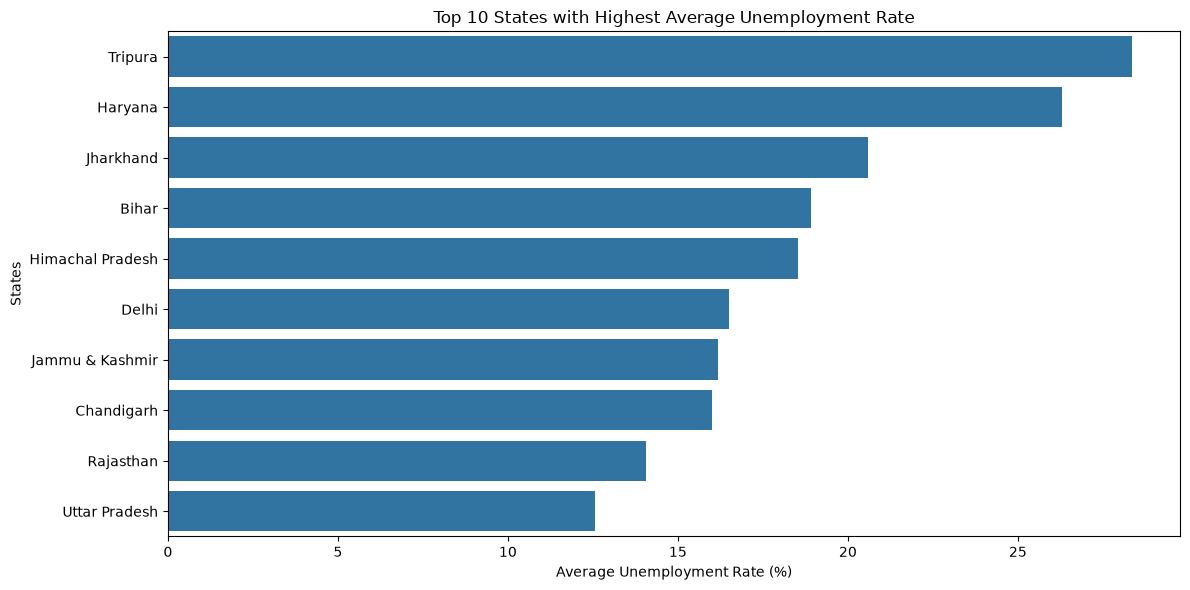

In [15]:
# Top 10 states with highest average unemployment rate

top_10_states = state_unemployment.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title("Top 10 States with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("States")

plt.tight_layout()
plt.show()

### Observations: Top 10 States with Highest Average Unemployment Rate

- Tripura has the highest average unemployment rate among the states.
- Haryana and Jharkhand are the second and third highest.
- Bihar and Himachal Pradesh also show relatively high unemployment rates.
- These findings highlight significant differences in unemployment rates across Indian states.

In [16]:
# Calculate monthly average unemployment rate

monthly_unemployment = (
    df1.groupby(df1["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
    ].mean()
)

print("Month-wise Average Unemployment Rate:")
display(monthly_unemployment)

Month-wise Average Unemployment Rate:


Date
2019-05     8.874259
2019-06     9.303333
2019-07     9.033889
2019-08     9.637925
2019-09     9.051731
2019-10     9.900909
2019-11     9.868364
2019-12     9.497358
2020-01     9.950755
2020-02     9.964717
2020-03    10.700577
2020-04    23.641569
2020-05    24.875294
2020-06    11.903600
Freq: M, Name: Estimated Unemployment Rate (%), dtype: float64

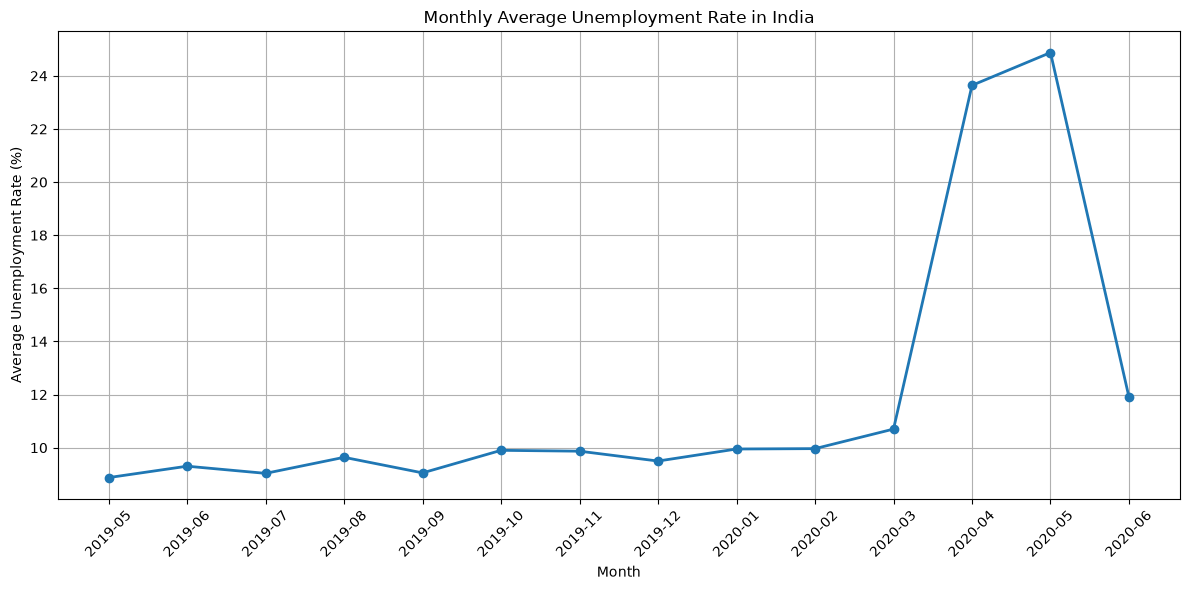

In [17]:
# Monthly unemployment rate trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index.astype(str),
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations: Month-wise Unemployment Trend

- During 2019, the average unemployment rate remained relatively stable, around 9–10%.
- The unemployment rate increased in March 2020.
- A sharp rise occurred in April and May 2020, reaching approximately 23.64% and 24.88%, respectively.
- In June 2020, the unemployment rate decreased to approximately 11.90%.
- This trend highlights the significant increase in unemployment during the early COVID-19 period.

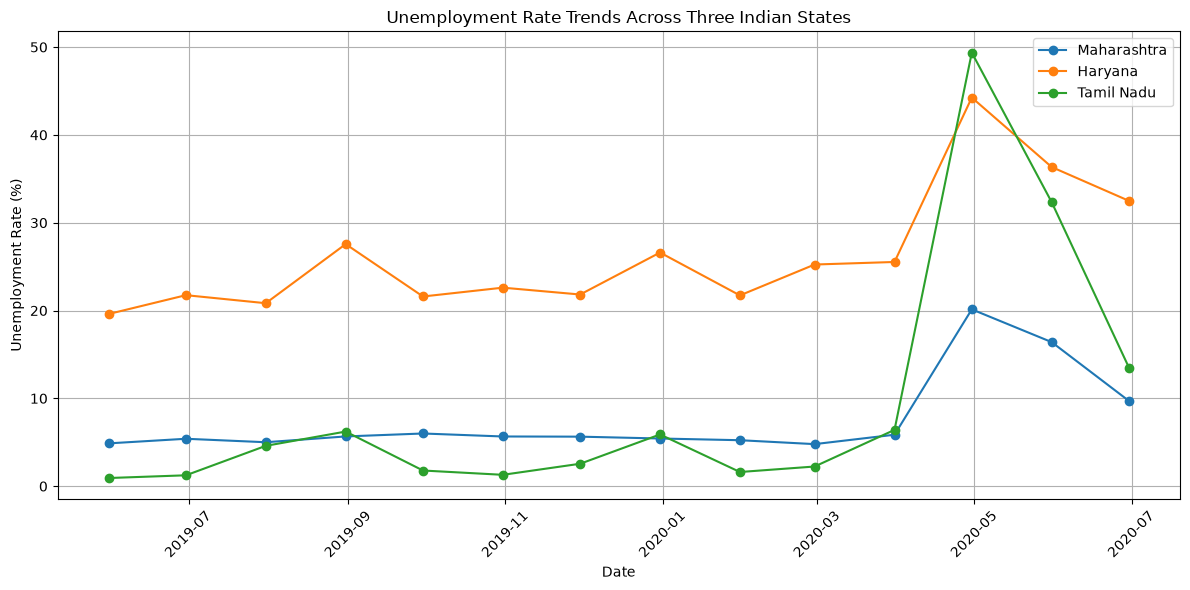

In [18]:
# Compare unemployment rates across three states

selected_states = ["Maharashtra", "Haryana", "Tamil Nadu"]

plt.figure(figsize=(12, 6))

for state in selected_states:
    state_data = df1[df1["Region"] == state]

    monthly_data = state_data.groupby("Date")[
        "Estimated Unemployment Rate (%)"
    ].mean()

    plt.plot(
        monthly_data.index,
        monthly_data.values,
        marker="o",
        label=state
    )

plt.title("Unemployment Rate Trends Across Three Indian States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations: Unemployment Trends Across Three States

- The unemployment rate varies across Maharashtra, Haryana, and Tamil Nadu.
- The three states show different unemployment patterns over the observed period.
- Unemployment rates changed noticeably during the COVID-19 period.
- Comparing these states helps identify regional differences in the impact of the pandemic.

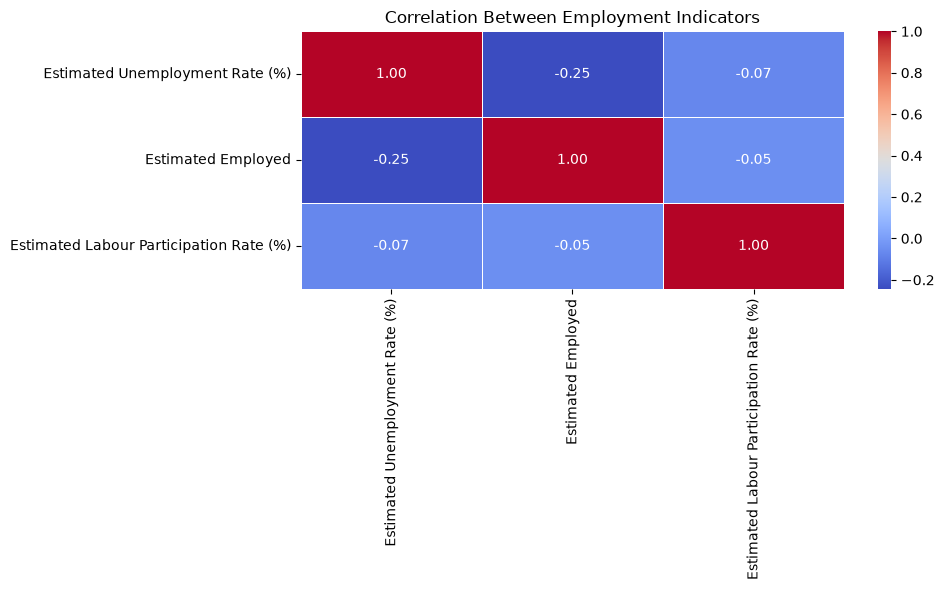

In [19]:
# Calculate correlation between employment indicators

correlation_data = df2[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

correlation_matrix = correlation_data.corr()

# Create correlation heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

### Observations: Correlation Between Employment Indicators

- The heatmap displays the correlation between estimated unemployment, estimated employment, and labour participation rates.
- Correlation values range from -1 to +1.
- A positive correlation indicates that two variables tend to increase or decrease together.
- A negative correlation indicates that one variable tends to increase when the other decreases.
- Correlation indicates an association between variables and does not establish a cause-and-effect relationship.

In [20]:
# Separate pre-COVID and COVID-period data

pre_covid = df1[df1["Date"] < "2020-03-01"]

covid_period = df1[df1["Date"] >= "2020-03-01"]

# Calculate average unemployment rates
pre_covid_rate = pre_covid["Estimated Unemployment Rate (%)"].mean()

covid_rate = covid_period["Estimated Unemployment Rate (%)"].mean()

print("Pre-COVID Average Unemployment Rate:",
      round(pre_covid_rate, 2), "%")

print("COVID-Period Average Unemployment Rate:",
      round(covid_rate, 2), "%")

Pre-COVID Average Unemployment Rate: 9.51 %
COVID-Period Average Unemployment Rate: 17.77 %


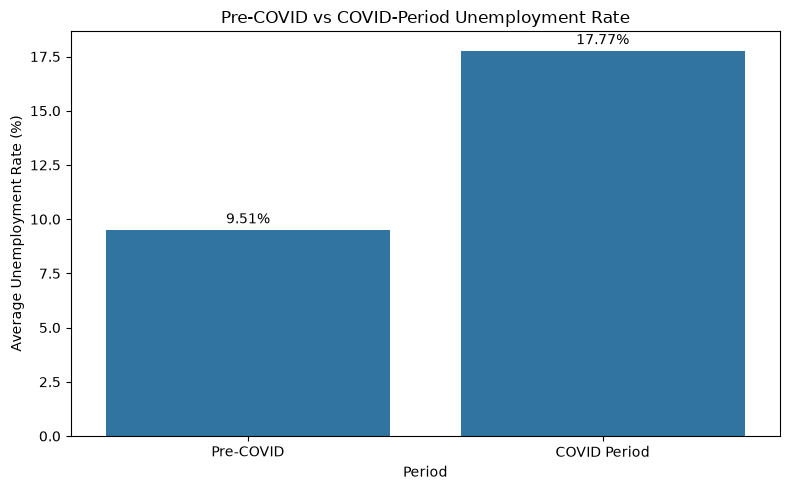

In [21]:
# Compare pre-COVID and COVID-period unemployment rates

periods = ["Pre-COVID", "COVID Period"]
rates = [pre_covid_rate, covid_rate]

plt.figure(figsize=(8, 5))

sns.barplot(x=periods, y=rates)

plt.title("Pre-COVID vs COVID-Period Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

for i, rate in enumerate(rates):
    plt.text(i, rate + 0.3, f"{rate:.2f}%", ha="center")

plt.tight_layout()
plt.show()

### Observations: Pre-COVID vs COVID Period

- The average unemployment rate before COVID-19 was 9.51%.
- During the COVID period, the average unemployment rate increased to 17.77%.
- This represents an increase of approximately 8.26 percentage points.
- The findings indicate a substantial rise in unemployment during the COVID-19 period in the dataset.
- These results show an association with the pandemic period and do not independently establish that COVID-19 caused the entire increase.

## Final Conclusion

This project successfully explored unemployment trends in India using Python and Exploratory Data Analysis techniques. The analysis provided insights into state-wise unemployment differences, monthly changes, regional patterns, and the relationship between important employment indicators.

The major findings of the analysis are:

1. **State-wise Analysis:** Tripura recorded the highest average unemployment rate of approximately 28.35%, followed by Haryana at 26.28% and Jharkhand at 20.59%. Meghalaya recorded the lowest average rate at approximately 4.80%.

2. **Monthly Trends:** Unemployment rates remained relatively stable during much of 2019 and early 2020, generally staying around 9–10%. However, a sharp increase was observed in April and May 2020, when the average unemployment rate reached approximately 23.64% and 24.88%, respectively.

3. **Regional Comparison:** The comparison of Maharashtra, Haryana, and Tamil Nadu showed that unemployment patterns differed across states, highlighting regional variations in the labour market.

4. **Correlation Analysis:** The correlation heatmap helped examine the relationships between estimated unemployment rates, estimated employment, and labour force participation rates. These relationships provide useful statistical insights but do not establish cause and effect.

5. **COVID-19 Impact Analysis:** The average unemployment rate before the selected COVID-19 period (before March 2020) was approximately 9.51%, while the average rate from March 2020 onward was approximately 17.77%. This represents an increase of approximately 8.26 percentage points.

Overall, the analysis indicates a substantial rise in unemployment during the COVID-19 period represented in the dataset. It also highlights considerable differences in unemployment rates across Indian states.

This project demonstrates how Python libraries can be used to clean, analyze, interpret, and visualize real-world data to identify meaningful patterns and trends.

### Limitations

- The datasets cover different time periods and contain slightly different columns.
- The analysis is based on the available dataset and may not represent the complete employment situation in India.
- The COVID-19 comparison shows an association with the pandemic period and does not prove that the pandemic alone caused the increase in unemployment.
- The correlation analysis identifies statistical relationships, not causal relationships.